# MGT5493 Programming in Business Analytics

#### Lab 3 — Exploratory Data Analysis & Visualization: Marketing Performance Analysis

#### Dataset: marketing_performance.csv

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# load dataset and inspection
df = pd.read_csv("marketing_performance.csv")
print(df.head(5), 
      "\n", 
      "=" * 100, 
      "\n", 
      df.describe(),
      "\n")
print(df.info())

     Month Region    Channel    Spend  Leads    Sales  Impressions  Clicks
0  2024-01     UK     Search  7266.49     69   809.75      1997616   50992
1  2024-01     UK     Social  9815.07     59   352.64      3829279  136825
2  2024-01     UK      Email  7179.70     33   325.66      2487039   70458
3  2024-01     UK    Display  8284.50    200  2388.13      2648817   84297
4  2024-01     UK  Affiliate  8761.09    195  2138.92      2025596   96537 
               Spend       Leads        Sales   Impressions         Clicks
count    360.000000  360.000000   360.000000  3.600000e+02     360.000000
mean    8039.740889  114.383333  1341.318250  2.394418e+06   71569.463889
std     2359.915147   60.364148  1057.792328  8.604514e+05   39838.922638
min     1240.460000   17.000000    48.920000  3.252440e+05    8371.000000
25%     6448.415000   70.750000   587.720000  1.795931e+06   41074.000000
50%     8014.905000   99.000000  1048.940000  2.305104e+06   62349.000000
75%     9394.600000  149.00000

In [3]:
# data cleaning 
print("Number of NaN in Region column:",df["Region"].isnull().sum())

df[df["Region"].isnull()]

Number of NaN in Region column: 90


,Month,Region,Channel,Spend,Leads,Sales,Impressions,Clicks
15,2024-01,NaN,Search,6583.22,109,2749.65,1558122,35461
16,2024-01,NaN,Social,6671.63,42,262.79,1740284,76215
17,2024-01,NaN,Email,6094.51,85,1112.67,1858528,20315
18,2024-01,NaN,Display,5897.63,57,665.18,1689016,71916
19,2024-01,NaN,Affiliate,8892.82,181,1147.88,2296533,48856
...,...,...,...,...,...,...,...,...
355,2025-06,NaN,Search,4792.13,46,524.30,1574137,74269
356,2025-06,NaN,Social,8732.69,87,1498.24,1792841,77495
357,2025-06,NaN,Email,9790.49,301,3746.06,3105103,150911
358,2025-06,NaN,Display,6775.37,74,1252.19,2629155,39363


In [4]:
# data cleaning 
df["Region"] = df["Region"].fillna("Unknown")
df["Region"].isnull().sum()

np.int64(0)

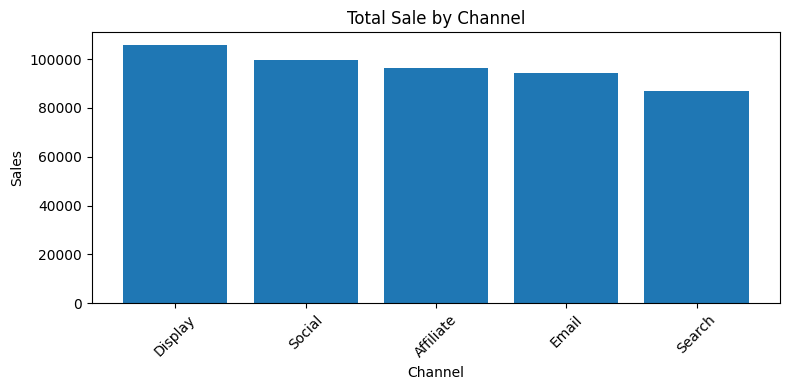

In [5]:
# Total sales by channel 

sales_channel = (
    df.groupby("Channel", as_index= False)['Sales']
    .sum()
    .sort_values(by = "Sales", ascending = False)
)

# plot sales of channel by bar chat:
plt.figure(figsize = (8,4))
plt.bar(sales_channel["Channel"], sales_channel["Sales"])
plt.title("Total Sale by Channel")
plt.xlabel("Channel")
plt.ylabel("Sales")
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

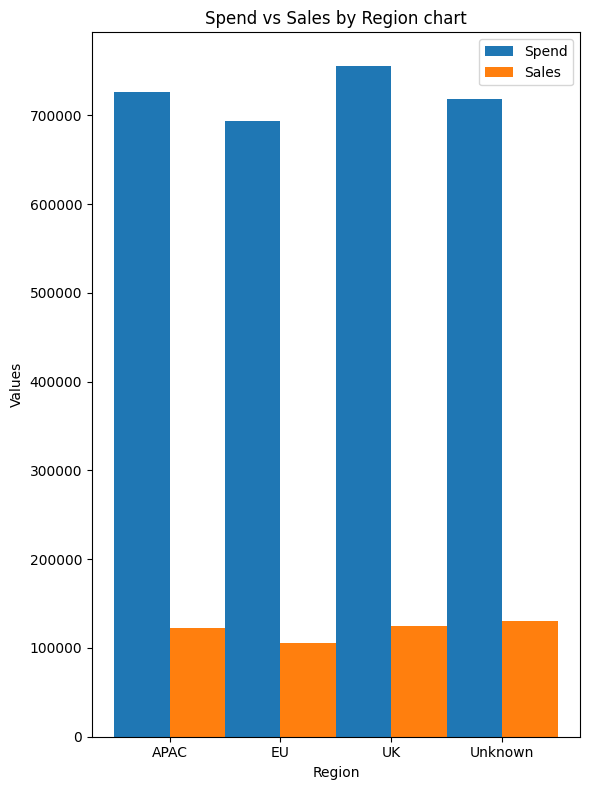

In [6]:
# spend vs. sales by region (side by side bars chart)

## table created by aggreation 
region_sum = df.groupby("Region")[["Spend", "Sales"]].sum()

## plot side by side bars
x = np.arange(len(region_sum.index))
width = 0.5

figure, ax = plt.subplots (figsize = (6,8))
ax.bar(x - width/2, region_sum['Spend'].values, width, label = 'Spend')
ax.bar(x + width/2, region_sum['Sales'].values, width, label = 'Sales')
ax.set_xticks(x)
ax.set_xticklabels(region_sum.index)
ax.set_title("Spend vs Sales by Region chart")
ax.set_xlabel("Region")
ax.set_ylabel("Values")
ax.legend()
plt.tight_layout()
plt.show()

       _Month  Monthly_Sales
0  2024-01-01       27227.55
1  2024-02-01       32326.95
2  2024-03-01       28380.19
3  2024-04-01       24535.92
4  2024-05-01       36459.33
5  2024-06-01       19983.57
6  2024-07-01       25263.72
7  2024-08-01       25569.97
8  2024-09-01       28050.44
9  2024-10-01       21318.05
10 2024-11-01       30053.17
11 2024-12-01       21432.56
12 2025-01-01       30775.05
13 2025-02-01       21722.25
14 2025-03-01       26825.73
15 2025-04-01       27863.13
16 2025-05-01       25573.82
17 2025-06-01       29513.17


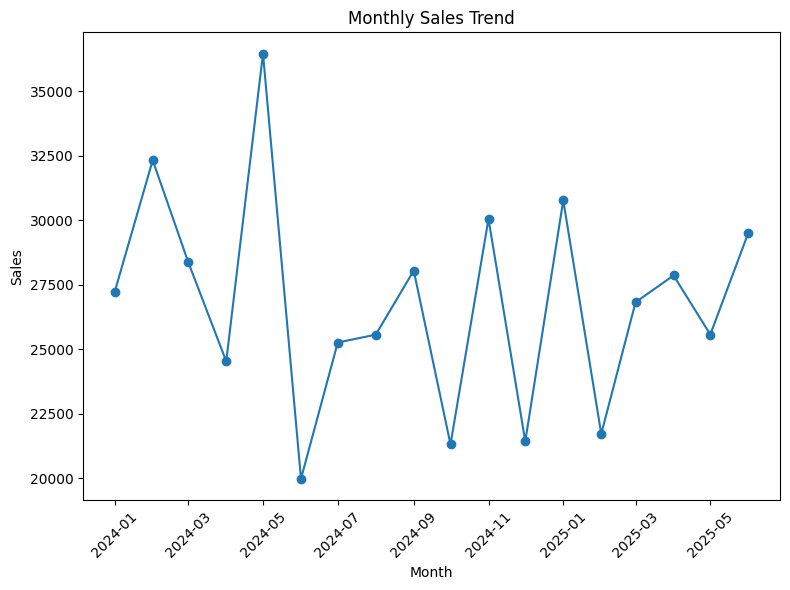

In [ ]:
# monthly sales trend:

## aggregation by month:
monthly_sales = (df.assign(_Month = pd.to_datetime(df['Month']))
                 .groupby('_Month', as_index = False)
                 .agg(Monthly_Sales = ('Sales', 'sum'))
                 .sort_values('_Month')
                 )
print(monthly_sales)

## plot the trend
plt.figure(figsize = (8,6))
plt.plot(monthly_sales['_Month'], monthly_sales['Monthly_Sales'], marker = 'o') # no plot type mentioned, default is line plot
plt.title("Monthly Sales Trend")
plt.xlabel('Month')
plt.ylabel('Sales')
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()


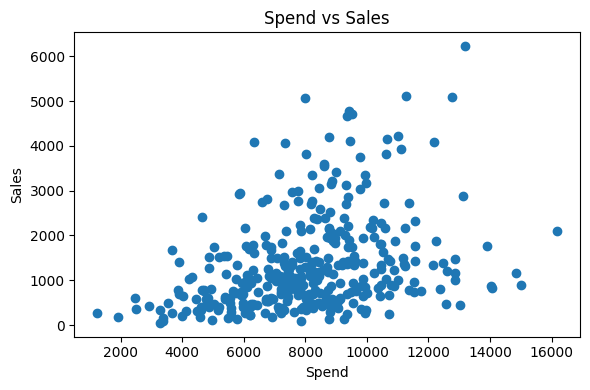

In [30]:
# Scatter plot: Spend vs Sales

plt.figure(figsize= (6, 4))
plt.scatter(df['Spend'], df['Sales'])
plt.title('Spend vs Sales')
plt.xlabel('Spend')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()

                Spend     Leads     Sales  Impressions    Clicks
Spend        1.000000  0.566594  0.340309     0.814143  0.522193
Leads        0.566594  1.000000  0.684837     0.494560  0.278217
Sales        0.340309  0.684837  1.000000     0.269639  0.147986
Impressions  0.814143  0.494560  0.269639     1.000000  0.637470
Clicks       0.522193  0.278217  0.147986     0.637470  1.000000


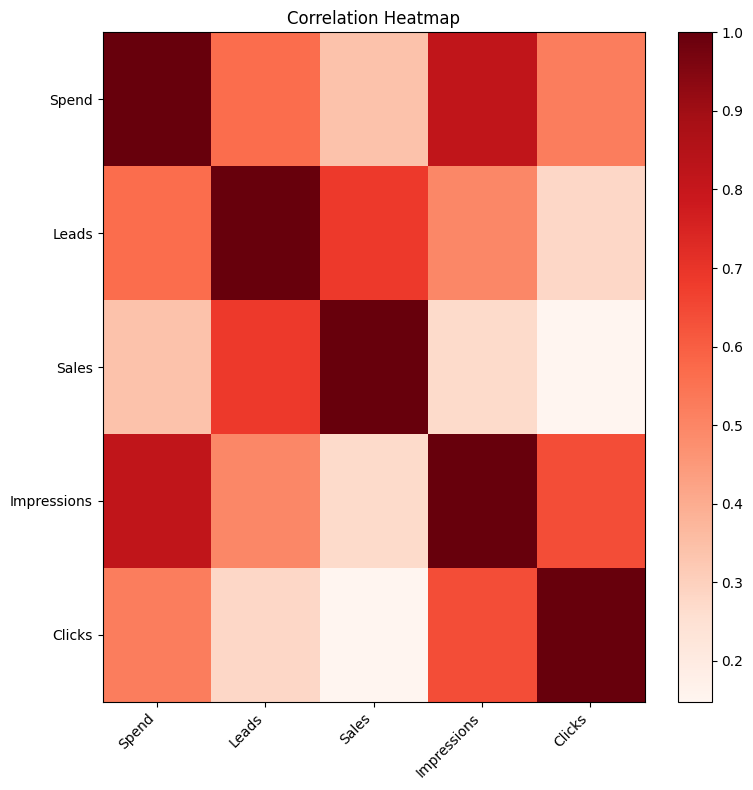

In [27]:
# Correlation heatmap:

## Calculate correlation map
num = df[['Spend', 'Leads', 'Sales', 'Impressions', 'Clicks']]
correlation = num.corr()
print(correlation)

## plot the heatmap:
plt.figure(figsize = (8,8))
plt.imshow(correlation, interpolation = 'nearest', aspect = 'auto', cmap="Reds")
plt.title('Correlation Heatmap')
plt.colorbar()
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation = 45, ha= 'right')
plt.yticks(range(len(correlation.index)), correlation.index)
plt.tight_layout()
plt.show()

# Trend **(Optional)**

Looking for the line trend based on the polynomial ranks:
- start with degree 1 , which basically is a OLS or linear regression
- try to test higher ranks: degree 2 and 3

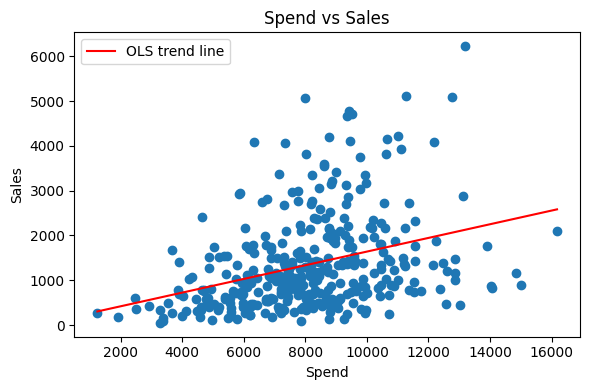

In [ ]:
# Scatter trend plot: Spend vs Sales

data = df[["Spend", "Sales"]].dropna()
x = data["Spend"]
y = data["Sales"]

## looking for coefficient by polynomial with 1 degree
b, a = np.polyfit(x, y, deg=1)
x_line = np.array([x.min(), x.max()])
y_line = b * x_line + a

plt.figure(figsize= (6, 4))
plt.scatter(x, y)
plt.plot(x_line, y_line, color="red", label="OLS trend line")
plt.title('Spend vs Sales')
plt.xlabel('Spend')
plt.ylabel('Sales')
plt.legend()
plt.tight_layout()
plt.show()

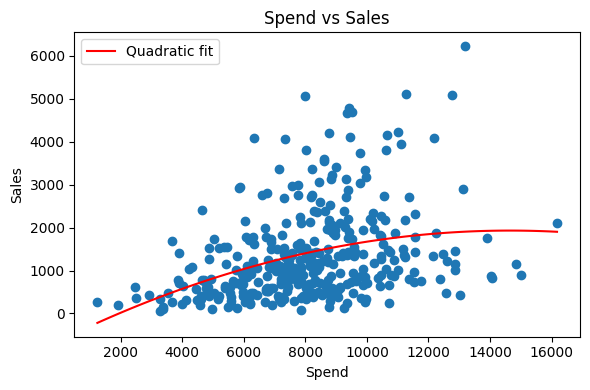

In [38]:
# Looking for high-rank polynomial results
b_2, b_1, a = np.polyfit(x, y, 2)

x_curve = np.linspace(x.min(), x.max(), 100)
y_curve = b_2 * x_curve**2 + b_1 * x_curve + a

plt.figure(figsize=(6, 4))
plt.scatter(x, y)
plt.plot(x_curve, y_curve, color="red", label="Quadratic fit")
plt.title("Spend vs Sales")
plt.xlabel("Spend")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

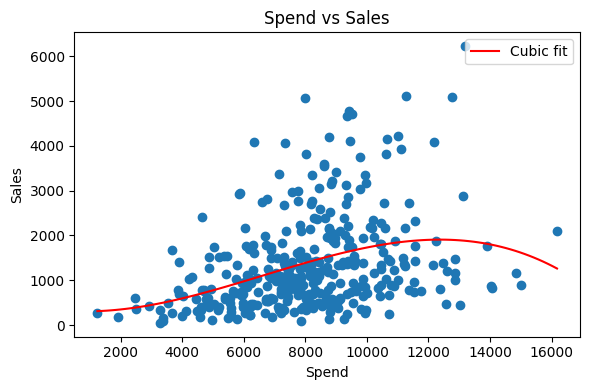

In [41]:
b_3, b_2, b_1, a = np.polyfit(x, y, 3)

x_curve = np.linspace(x.min(), x.max(), 100)
y_curve = b_3 * x_curve**3+ b_2 * x_curve**2 + b_1 * x_curve + a

plt.figure(figsize=(6, 4))
plt.scatter(x, y)
plt.plot(x_curve, y_curve, color="red", label="Cubic fit")
plt.title("Spend vs Sales")
plt.xlabel("Spend")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [42]:
from sklearn.model_selection import KFold

data = df[["Spend", "Sales"]].dropna()
x = data["Spend"].to_numpy()
y = data["Sales"].to_numpy()

cv = KFold(n_splits=5, shuffle=True, random_state=42)
rmse_by_degree = {}

for degree in range(1, 6):
    squared_errors = []

    for train, test in cv.split(x):
        coefficients = np.polyfit(x[train], y[train], degree)
        predicted = np.polyval(coefficients, x[test])
        squared_errors.extend((y[test] - predicted) ** 2)

    rmse_by_degree[degree] = np.sqrt(np.mean(squared_errors))
    print(f"Degree {degree}: RMSE = {rmse_by_degree[degree]:.2f}")

best_degree = min(rmse_by_degree, key=rmse_by_degree.get)
print(f"Best degree: {best_degree}")

Degree 1: RMSE = 995.64
Degree 2: RMSE = 993.69
Degree 3: RMSE = 997.26
Degree 4: RMSE = 1000.29
Degree 5: RMSE = 998.11
Best degree: 2


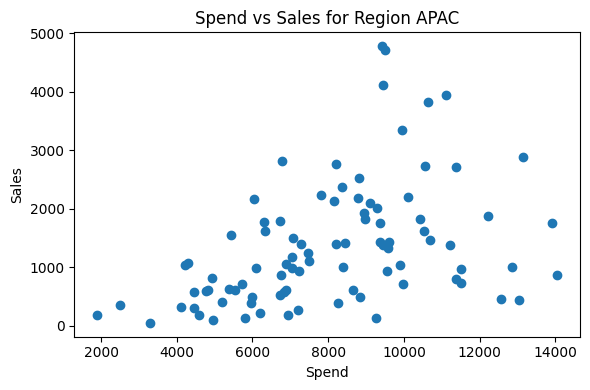

In [46]:
# plot a single region scatter figure of Spend vs Sales for APAC
APAC_ss = df[df["Region"] == "APAC"]
APAC_ss

plt.figure(figsize = (6,4))
plt.scatter(APAC_ss['Spend'], APAC_ss['Sales'])
plt.title('Spend vs Sales for Region APAC')
plt.xlabel('Spend')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()

# the dataset represents heteroscedasticity
# convergence vs divergence 

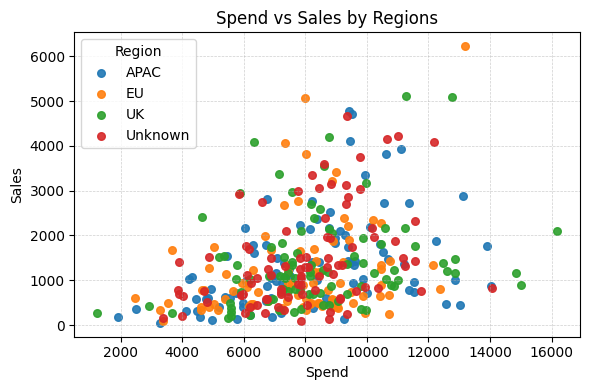

In [29]:
# identify spend vs sales for different regions 
fig, ax = plt.subplots(figsize = (6, 4))
for region, s_df in df.groupby('Region'):
    ax.scatter(s_df['Spend'], s_df['Sales'], s=30, alpha=0.9, label = region)
ax.set_title('Spend vs Sales by Regions')
ax.set_xlabel('Spend')
ax.set_ylabel('Sales')
ax.legend(title = 'Region', ncol = 1) # tweak layout as needed
ax.grid(True, linestyle = '--', linewidth=0.5, alpha = 0.6)
plt.tight_layout()
plt.show()